Mean-Covariance Practical Project

5 tasks

1. Data -> Download prices split 2024/2025, compute and plot returns
2. Estimation -> Choose flexible probabilities, compute the effective number of scenarios (ens)
estimate mean and covariance
3. Model -> Principal-component LFM: eigenvalue plot: r² vs number of factors: σ² and k̄
4. Evaluation -> Use the 2024 model to predict 2025 returns, plot predicted vs actual
5. Interpretation -> Read the first 2 eigenvectors as portfolios, plot their 2025 returns
explain them financially.

Objective:
Designed to give hands-on experience in building a principal component linear factor model (LFM) to understand and
capture the key drivers of a market of technology stocks.
I will use my model to identify underlying risk factors and construct diversified portfolios that
reflect these factors.

Background:
In vesting in individual technology stocks can be costly and leaves retail investors under-diversified.
One way to solve this is by creating factor portfolios that capture the main sources of co-movement in th sector.
In this project, I will build a principal component linear factor model (LFM) to construct such portfolios,
test their predictive performance, and interpret the economic meaning of the most important factors.

Market:
The market consists of 14 technology stocks plus one risk-free instrument.
The stocks are: AAPL, MSFT, GOOGL, AMZN, META, CSCO, NVDA, ORCL, PLTR, SAP, IBM, CRM, SHOP, UBER.

Data:
- Training data: Daily linear returns in 2024.
- Testing data: Daily linear returns from 1 Jan 2025 to 30 Sept 2025.
- Assumptions: Returns are stationary and ergodic;  I may fit a static LFM.
Portfolios with weights not summing to one are adjusted via the risk-free instrument.

Prepare the environment

In [1]:
# Imports cell
from yfinance import download
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pca_lab.pca import r_squared


# Task 1: Data Preparation
The approach,
There are 3 jobs:

1. Download adjusted close prices for the 14 stocks from Jan 2024 to Sept 2025, using package yfinance
2. Turn prices into f=daily linear returns: R_t = P_t /P_{t-1}-1.
These are the target variables X that the model explains, the same as in s_pca_truncated_lfm.
3. Split into training (2024) and testing(2025) datasets.
Fit everything on 2024, then check whether it still works on 2025 data the model has never seen.
4. Compute and plot daily linear returns for each stock.

In [2]:
# list of technology stock tickers
tickers = ['AAPL','MSFT', 'GOOGL', 'AMZN', 'META', 'CSCO', 'NVDA', 'ORCL', 'PLTR', 'SAP', 'IBM', 'CRM', 'SHOP', 'UBER']

# date range
start_date = "2024-01-01"
# changed end_date to include 30th September (as defined in the brief)
end_date = "2025-10-01"

# daily adjusted closing prices
# rows = trading days
# columns = stocks
data = download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']
data

# Check Adj Close prices for all stocks are complete
close_prices = data.dropna(how='all')
print('Missing Adj Close prices per stock : ')
print(close_prices.isna().sum().to_string())
print()

# Daily linear returns: todays_return = todays_price / yesterdays_price -1
# pct_change does this for every stock at once,
# The first row is Nan (due to no previous day) so we drop it here
# returns are calculated on the whole price history before splitting
daily_linear_returns = close_prices.pct_change().dropna()

# Splitting (after daily linear returns calc) into training dataset (2024) and testing dataset (2025)
training_returns = daily_linear_returns.loc['2024-01-01' : '2024-12-31']
testing_returns = daily_linear_returns.loc['2025-01-01' : '2025-10-01']

print('\nTraining: ', training_returns.shape, 'from',
      training_returns.index[0].date(), 'to', training_returns.index[-1].date())
print()
print('\nTesting: ', testing_returns.shape, 'from',
      testing_returns.index[0].date(), 'to', testing_returns.index[-1].date())
print()

# Plot daily returns, one panel per stock
axes = daily_linear_returns.plot(subplots=True, layout=(7,2), figsize=(14,8),
                                 sharex=True, legend=False, linewidth=0.6)

for ax, ticker in zip(axes.flatten(), daily_linear_returns.columns):
    ax.set_title(ticker, fontsize=10)
    ax.axvline(pd.Timestamp('2025-01-01'), color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='grey', linewidth=0.5)

plt.suptitle('Daily linear returns (red dashed line = train/test split)', y=1.0)
plt.tight_layout()
plt.show()

# Summary of the training data
training_summary = pd.DataFrame({
    'mean daily return (%)': 100 * training_returns.mean(),
    'daily volatility (%)': 100 * training_returns.std(),
    'worst day (%)': 100 * training_returns.min(),
    'best day (%)': 100 * training_returns.max(),
}).round(2)
print(training_summary.sort_values('daily volatility (%)', ascending=False))


[*********************100%***********************]  14 of 14 completed


Missing Adj Close prices per stock : 
Ticker
AAPL     0
AMZN     0
CRM      0
CSCO     0
GOOGL    0
IBM      0
META     0
MSFT     0
NVDA     0
ORCL     0
PLTR     0
SAP      0
SHOP     0
UBER     0


Training:  (251, 14) from 2024-01-03 to 2024-12-31


Testing:  (186, 14) from 2025-01-02 to 2025-09-30



<Figure size 1400x800 with 14 Axes>

        mean daily return (%)  daily volatility (%)  worst day (%)  \
Ticker                                                               
PLTR                     0.68                  4.05         -15.11   
SHOP                     0.20                  3.32         -18.59   
NVDA                     0.46                  3.31         -10.00   
UBER                     0.04                  2.51          -9.60   
META                     0.24                  2.30         -10.56   
CRM                      0.13                  2.26         -19.74   
ORCL                     0.21                  2.03          -6.67   
AMZN                     0.17                  1.77          -8.78   
GOOGL                    0.14                  1.77          -7.50   
SAP                      0.21                  1.57          -5.32   
IBM                      0.15                  1.47          -8.25   
AAPL                     0.13                  1.41          -4.82   
MSFT                

# Task 2: Estimation

- Choose and justify a set of flexible probabilities for the training data.
- Compute the effective number of scenarios.
- Estimate the mean and covariance of training returns.  Explain and defend my chosen estimations method.

Probabilities sum to:  1.0
Newest day weight / oldest day weight:  3.96

effective_number_of_scenarios with 126-day half-life: 232.7 out of 251 days
effective_number_of_scenarios with equal weights:    251.0



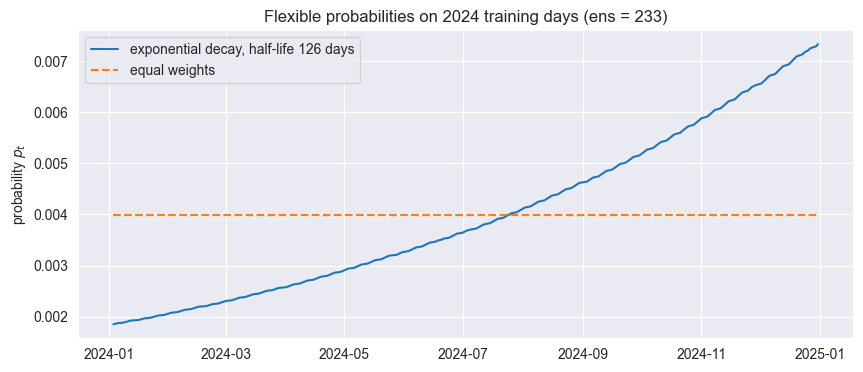

In [3]:
# your code here
# Flexible probabilities: Exponential decay
# 252 days x 14 stocks, one row per day
returns_matrix = training_returns.to_numpy()
# t_bar, n_bar
number_of_days, number_of_stocks = returns_matrix.shape

# tau_HL: ~ 6 months of trading days
half_life_days = 126

# label each day by how far it is from 31 Dec 2024
# How many days before the last training day each row is: 250, 249, ....,1, 0
days_before_last = np.arange(number_of_days)[::-1]

# giving each day a weight, that will halve every 126 days
# w_t = exp(-(ln2 / tau_HL) * distance), then normalise so the weights sum to 1
decay_weights = np.exp(-np.log(2) / half_life_days * days_before_last)

# rescale the weights so they add up to 1 (turns them into probabilities)
flexible_probabilities = decay_weights / decay_weights.sum()

# Benchmark: equal weights p_t = 1 / t_bar
equal_probabilities = np.full(number_of_days, 1 / number_of_days)

# Confirming the probabilities
print('Probabilities sum to: ', flexible_probabilities.sum().round(6))
print('Newest day weight / oldest day weight: ', (flexible_probabilities[-1] / flexible_probabilities[0]).round(2))
print()

# Effective number of scenarios: ens = exp(-sum p ln p)
def effective_number_of_scenarios(probabilities):
    # Entropy based 'ens' : how many equally weighted days the weights are worth
    return np.exp(-probabilities @ np.log(probabilities))

effect_num_scenarios_decay = effective_number_of_scenarios(flexible_probabilities)
effect_num_scenarios_equal = effective_number_of_scenarios(equal_probabilities)
print(f'effective_number_of_scenarios with {half_life_days}-day half-life: {effect_num_scenarios_decay:.1f} out of {number_of_days} days')
print(f'effective_number_of_scenarios with equal weights:    {effect_num_scenarios_equal:.1f}')
print()

# Plotting the weights
plt.figure(figsize=(10, 4))
plt.plot(training_returns.index, flexible_probabilities, label=f'exponential decay, half-life {half_life_days} days')
plt.plot(training_returns.index, equal_probabilities, linestyle='--', label='equal weights')
plt.ylabel('probability $p_t$')
plt.title(f'Flexible probabilities on 2024 training days (ens = {effect_num_scenarios_decay:.0f})')
plt.legend()
plt.show()
print()

In [4]:
# HFP mean and covariance
"""
Historical-with-flexible-probabilities estimators
returns: (t_bar X n_bar) array, one row per day.
Probabilities: (t_bar,) weights summing to 1
"""
def hfp_mean_and_covariance(returns, probabilities):
    # multiply 251 weights by 251 returns and add up separately
    mean = probabilities @ returns
    # each days return minus that stocks mean
    deviations = returns - mean
    covariance = (deviations * probabilities[:, None]).T @ deviations
    return mean, covariance

# Main estimate: exponential-decay probabilities
mean_hfp, covariance_hfp = hfp_mean_and_covariance(returns_matrix, flexible_probabilities)

# Benchmark: equal weights
mean_equal, covariance_equal = hfp_mean_and_covariance(returns_matrix, equal_probabilities)

# Wrapping labelled DataFrames so the stock names stay attached
stock_names = training_returns.columns
mean_hfp = pd.Series(mean_hfp, index=stock_names)
covariance_hfp = pd.DataFrame(covariance_hfp, index=stock_names, columns=stock_names)

# Volatilities and correlation implied by the HFP covariance
volatility_hfp = np.sqrt(np.diag(covariance_hfp))
correlation_hfp = covariance_hfp / np.outer(volatility_hfp, volatility_hfp)

print('HFP mean daily return (%): ')
display((100 * mean_hfp).round(3).to_frame('mean (%)').T)
print()
print('HFP covariance (x 10^4, i.e. in %^2):')
display((1e4 * covariance_hfp).round(2))
print()
print('HFP correlation:')
display(correlation_hfp.round(2))

HFP mean daily return (%): 


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
mean (%),0.151,0.168,0.163,0.12,0.144,0.134,0.178,0.033,0.33,0.177,0.776,0.188,0.281,-0.047



HFP covariance (x 10^4, i.e. in %^2):


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Ticker,,,,,,,,,,,,,,
AAPL,1.86,0.86,0.46,0.27,0.85,0.26,0.80,0.86,1.20,0.66,1.18,0.74,1.15,0.49
AMZN,0.86,3.25,1.53,0.77,1.76,0.65,2.12,1.58,2.43,1.56,2.22,1.05,2.79,1.10
CRM,0.46,1.53,5.10,0.90,1.19,0.95,1.24,1.15,2.33,1.72,1.64,1.61,2.32,1.20
CSCO,0.27,0.77,0.90,1.29,0.47,0.61,0.28,0.46,0.64,0.61,1.10,0.36,0.99,0.51
GOOGL,0.85,1.76,1.19,0.47,3.14,0.21,1.62,1.24,1.80,0.80,1.03,0.73,1.71,0.48
IBM,0.26,0.65,0.95,0.61,0.21,2.04,0.70,0.50,0.79,0.90,1.12,0.59,0.98,0.47
META,0.80,2.12,1.24,0.28,1.62,0.70,4.31,1.55,2.59,1.23,2.28,1.24,2.18,1.27
MSFT,0.86,1.58,1.15,0.46,1.24,0.50,1.55,1.61,1.83,1.39,1.54,0.97,1.57,0.85
NVDA,1.20,2.43,2.33,0.64,1.80,0.79,2.59,1.83,10.19,2.80,3.58,2.06,2.57,2.08



HFP correlation:


Ticker,AAPL,AMZN,CRM,CSCO,GOOGL,IBM,META,MSFT,NVDA,ORCL,PLTR,SAP,SHOP,UBER
Ticker,,,,,,,,,,,,,,
AAPL,1.00,0.35,0.15,0.17,0.35,0.13,0.28,0.50,0.28,0.24,0.22,0.36,0.25,0.14
AMZN,0.35,1.00,0.38,0.38,0.55,0.25,0.56,0.69,0.42,0.42,0.31,0.38,0.46,0.24
CRM,0.15,0.38,1.00,0.35,0.30,0.30,0.26,0.40,0.32,0.37,0.18,0.46,0.31,0.21
CSCO,0.17,0.38,0.35,1.00,0.24,0.38,0.12,0.32,0.18,0.26,0.24,0.21,0.26,0.18
GOOGL,0.35,0.55,0.30,0.24,1.00,0.08,0.44,0.55,0.32,0.22,0.15,0.27,0.29,0.11
IBM,0.13,0.25,0.30,0.38,0.08,1.00,0.24,0.28,0.17,0.31,0.20,0.27,0.20,0.13
META,0.28,0.56,0.26,0.12,0.44,0.24,1.00,0.59,0.39,0.29,0.28,0.39,0.31,0.24
MSFT,0.50,0.69,0.40,0.32,0.55,0.28,0.59,1.00,0.45,0.54,0.30,0.50,0.37,0.26
NVDA,0.28,0.42,0.32,0.18,0.32,0.17,0.39,0.45,1.00,0.43,0.28,0.42,0.24,0.26


In [5]:
# Sanity checks - also decay vs equal comparison

# Equal-weight HFP must equal numpy's ample covariance with ARPM's 1/t_bar convention
print('Equal-weight HFP matches np.cov(bias=True):  ',
      np.allclose(covariance_equal, np.cov(returns_matrix.T, bias=True)))
print()

# A valid covariance is symmetric with all eigenvalues > 0
eigenvalues_check = np.linalg.eigvalsh(covariance_hfp)
print('Symmetric: ', np.allclose(covariance_hfp, covariance_hfp.T),
      '| smallest eigenvalue > 0: ', eigenvalues_check.min() > 0)
print()

# How precisely is each mean estimated? standard error ~ volatility / sqrt(ens)
estimate_comparison = pd.DataFrame({
    'mean, decay (%)': 100 * mean_hfp,
    'mean, equal (%)': 100 * mean_equal,
    'std error of mean (%)': 100 * volatility_hfp / np.sqrt(effect_num_scenarios_decay),
    'vol, decay (%)': 100 * volatility_hfp,
    'vol, equal (%)': 100 * np.sqrt(np.diag(covariance_equal)),
}, index=stock_names).round(3)
display(estimate_comparison)

# How different is the covariance under the 2 weighting schemes? (relative Frobenius distance)
relative_difference = np.linalg.norm(covariance_hfp.to_numpy() - covariance_equal) / np.linalg.norm(covariance_equal)
print(f'Covariance: decay vs equal weights differ by {100 * relative_difference:.1f}%')
print()

# Average pairwise correlation: a first hint of how strong the tech market factor is
average_correlation = correlation_hfp.to_numpy()[np.triu_indices(number_of_stocks, 1)].mean()
print(f'Pairwise correlation: {average_correlation:.2f}')

Equal-weight HFP matches np.cov(bias=True):   True

Symmetric:  True | smallest eigenvalue > 0:  True



,"mean, decay (%)","mean, equal (%)",std error of mean (%),"vol, decay (%)","vol, equal (%)"
Ticker,,,,,
AAPL,0.151,0.131,0.089,1.362,1.409
AMZN,0.168,0.167,0.118,1.803,1.767
CRM,0.163,0.135,0.148,2.259,2.257
CSCO,0.120,0.082,0.074,1.134,1.135
GOOGL,0.144,0.142,0.116,1.772,1.765
IBM,0.134,0.148,0.094,1.429,1.471
META,0.178,0.237,0.136,2.077,2.293
MSFT,0.033,0.062,0.083,1.267,1.254
NVDA,0.330,0.463,0.209,3.192,3.301


Covariance: decay vs equal weights differ by 6.3%

Pairwise correlation: 0.30


Data choices (Task 1):

Prices are adjusted prices for splits and dividends, so returns are total returns.

Returns were computed on the full price series before splitting, which keeps the 2nd of Jan 2025 return value.

This is not leakage: a linear return series uses only the current and previous day's prices and estimates
nothing from the data.
All estimates below use 2024 data only.

Flexible probabilities (what I chose and why):

I gave recent days more weight than older days using exponential decay with a half-life of 126 trading
days (approx 6 months).
This means a day's weight halves for every 6 months you go back.
The last day of 2024 counts about 4 x as much as the first day.

Why not equal weights?

Equal weights treat January 2024 as just as relevant as December 2024.  The model will be used on 2025,
so I wanted the most recent behaviour to count a bit more.

Why not a shorter half-life?

There is only 1 year of data,  a short half-life (1 month) would throw most of it away, 6 months gives a
sensible tilt without throwing away to much.


Effective number of scenarios:

effective_number_of_scenarios = 232.7 of 251 days,
In other words, my weighting is worth about 233 equally weighted days,  so i keep approx 93% of
the information in the data, the tilt towards recent days costs very little

How reliable are the estimates?

The covariance is reliable.  Switching between decay and equal weights changes it by only 6.3%,
and most stock's volatilities change by less than 0.05%, the weighting choice doesnt change the picture.
The 'means' are much less reliable.

Their uncertainty (standard error) is about as big as the means themselves:
Only PLTR (0.78% a day) is clearly above zero.
As can be seen MSFT and UBER are indistinguishable from zero, and UBERs mean even changes sign between
the 2 weightings.

Possible improvements:

A robust estimate that down-weights extreme days, such as a Student-t (MLFP) fit,
and shrinking the noisy mean towards a common value.

# Task 3: Model Building

- Build a principal component LFM on the training data.
- Plot the eigenvalues of the rescaled covariance matrix from largest to smallest.
- Compute the r-squared for each number of included factors and plot r-squared vs factor count.
- Discuss your choices of scaling matrix and number of factors.

In [6]:
# scaling matrix: sigma = Diag(volatilities)
# sigma
scale_matrix = np.diag(volatility_hfp)
# inverse sigma
inverse_scale_matrix = np.diag(1 / volatility_hfp)

# Rescaled covariance: sigma^-1 * covariance * sigma^-1 (= the HFP correlation matrix)
rescaled_covariance = inverse_scale_matrix @ covariance_hfp.to_numpy() @ inverse_scale_matrix

# Eigen decomposition
# eigh returns ascending order
eigenvalues, eigenvectors = np.linalg.eigh(rescaled_covariance)
# largest eigenvalue first
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]

# Sign convention: make the largest entry (by size) of each eigenvector +ve
row_of_largest_entry = np.argmax(np.abs(eigenvectors), axis=0)
columns_to_flip = eigenvectors[row_of_largest_entry, np.arange(number_of_stocks)] < 0
eigenvectors[:, columns_to_flip] = -eigenvectors[:, columns_to_flip]

# r_squared for k = 1,2,3...,14 factors
r_squared_by_number_factors = np.cumsum(eigenvalues) / np.sum(eigenvalues)

# Noise edge (Marchenko-Pastur upper edge)
# q = n_bar / effective_number_of_scenarios
dimension_ratio = number_of_stocks / effect_num_scenarios_decay
# assumes noise variance 1
noise_edge = (1 + np.sqrt(dimension_ratio)) ** 2
# variance left after factor 1
noise_variance_adjusted = eigenvalues[1:].mean()
noise_edge_adjusted = noise_variance_adjusted * (1 + np.sqrt(dimension_ratio)) ** 2

print('Eigenvalues add up to ', eigenvalues.sum().round(4), '(= number of stocks, as expected for a correlation matrix)')
print()
print(f'Noise edge: {noise_edge:.2f} (basic) | {noise_edge_adjusted:.2f} (adjusted for factor 1)')
print()

eigen_table = pd.DataFrame({
    'eigenvalue': eigenvalues,
    'share of variance (%)': 100 * eigenvalues / eigenvalues.sum(),
    'cumulative r-squared (%)': 100 * r_squared_by_number_factors,
    'above basic noise edge': eigenvalues > noise_edge,
    'above adjusted noise edge': eigenvalues > noise_edge_adjusted,
}, index=pd.Index(range(1, number_of_stocks + 1),  name='factor k')).round(2)
display(eigen_table)

Eigenvalues add up to  14.0 (= number of stocks, as expected for a correlation matrix)

Noise edge: 1.55 (basic) | 1.06 (adjusted for factor 1)



,eigenvalue,share of variance (%),cumulative r-squared (%),above basic noise edge,above adjusted noise edge
factor k,,,,,
1,5.13,36.62,36.62,True,True
2,1.26,9.02,45.64,False,True
3,1.03,7.38,53.02,False,False
4,1.01,7.21,60.23,False,False
5,0.84,6.01,66.23,False,False
6,0.77,5.50,71.74,False,False
7,0.72,5.11,76.85,False,False
8,0.64,4.57,81.42,False,False
9,0.64,4.54,85.95,False,False


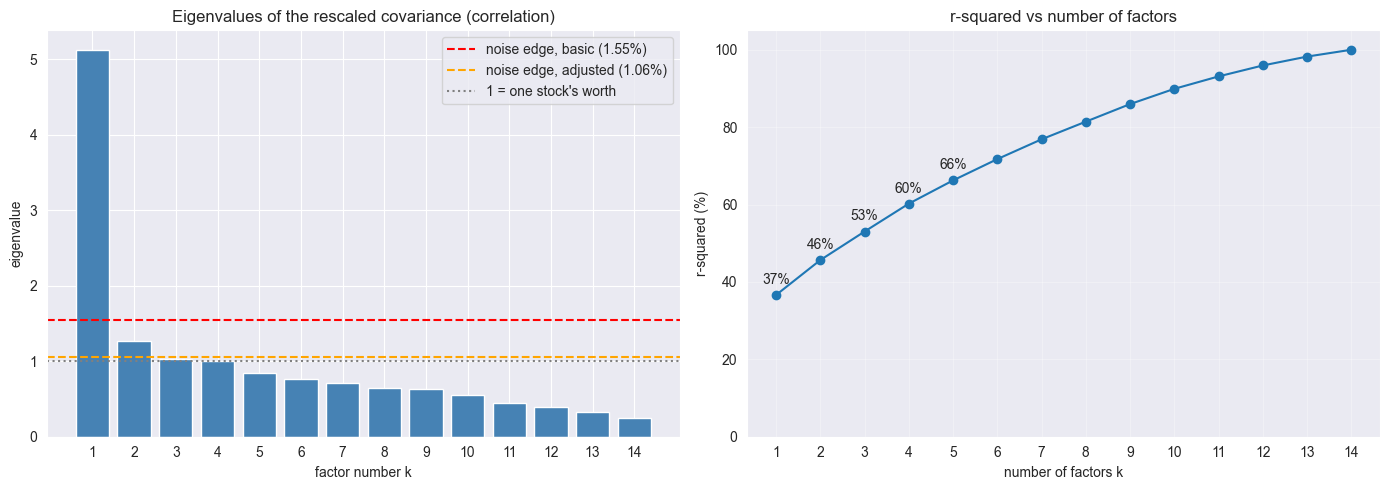

In [8]:
# Plots

factor_numbers = np.arange(1, number_of_stocks + 1)

fig, (ax_eig, ax_r2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: eigenvalues of the rescaled covariance, largest to smallest
ax_eig.bar(factor_numbers, eigenvalues, color='steelblue')
ax_eig.axhline(noise_edge, color='red', linestyle='--', label=f'noise edge, basic ({noise_edge:.2f}%)')
ax_eig.axhline(noise_edge_adjusted, color='orange', linestyle='--', label=f'noise edge, adjusted ({noise_edge_adjusted:.2f}%)')
ax_eig.axhline(1, color='grey', linestyle=':', label='1 = one stock\'s worth')
ax_eig.set(xlabel='factor number k', ylabel='eigenvalue', xticks=factor_numbers,
           title='Eigenvalues of the rescaled covariance (correlation)')
ax_eig.legend()

# Plot 2: r-squared vs number of factors
ax_r2.plot(factor_numbers, 100 * r_squared_by_number_factors, marker='o')
for k, r2 in zip(factor_numbers[:5], r_squared_by_number_factors[:5]):
    ax_r2.annotate(f'{100 * r2:.0f}%', (k, 100 * r2), textcoords='offset points', xytext=(0,8), ha='center')

ax_r2.set(xlabel='number of factors k', ylabel='r-squared (%)', xticks=factor_numbers,
          ylim=(0, 105), title='r-squared vs number of factors')
ax_r2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Building the model with my chose k_bar

# This has been set after looking at the plots above
number_of_factors = 2

# Loadings beta = sigma * e_(1:k)': how much each stock moves per unit of each factor
# 14 x k
factor_loadings = scale_matrix @ eigenvectors[:, :number_of_factors]

# construction matrix gamma = e_(1;k)' * sigma^-1: recipe to build factors from the returns
#  k x 14
factor_construction_matrix = eigenvectors[:, :number_of_factors].T @ inverse_scale_matrix

# Intercepts alpha = HFP mean
intercepts = mean_hfp.to_numpy()

# Factor returns on each training day: z_t = gamma (x_t - m)
factor_returns_train = (returns_matrix - intercepts) @ factor_construction_matrix.T

# Model's fitted returns and the leftover residuals
fitted_returns_train = intercepts * factor_returns_train @ factor_loadings.T
residual_returns_train = returns_matrix - fitted_returns_train

# Checks: does the model behave as the theory says?
# 1 - gamma * beta = identity (compress then expand gives the factor back)
print('gamma @ beta = identity: ', np.allclose(factor_construction_matrix @ factor_loadings, np.eye(number_of_factors)))
print()

# 2 - Factors are uncorrelated, with variances = the eigenvalues using the same HFP weights
print()
print()
print()
print()